## Konversi ppt -> Be

Tabel Referensi: https://www.handymath.com/cgi-bin/nacltble.cgi?submit=Entry

Tabel Referensi densitas air: https://openstax.org/books/chemistry-atoms-first/pages/e-water-properties

In [9]:
import numpy as np

salinities = np.array(
    [0, 10, 20, 40, 80, 120, 160, 200, 240, 260],
    dtype=float
)

temperatures = np.array([0, 10, 25, 40, 60, 80, 100], dtype=float)

# Densitas (kg/L)

densities = np.array([
    [0.9998395, 0.9997026, 0.9970479, 0.9922,  0.9832, 0.9718, 0.9584], # 0 ppt
    [1.00747,   1.00707,   1.00409,   0.99908, 0.9900, 0.9785, 0.9651], # 10 ppt
    [1.01509,   1.01442,   1.01112,   1.00593, 0.9967, 0.9852, 0.9719], # 20 ppt
    [1.03038,   1.02920,   1.02530,   1.01977, 1.0103, 0.9988, 0.9855], # 40 ppt
    [1.06121,   1.05907,   1.05412,   1.04798, 1.0381, 1.0264, 1.0134], # 80 ppt
    [1.09244,   1.08946,   1.08365,   1.07699, 1.0667, 1.0549, 1.0420], # 120 ppt
    [1.12419,   1.12056,   1.11401,   1.10688, 1.0962, 1.0842, 1.0713], # 160 ppt
    [1.15663,   1.15254,   1.14533,   1.13774, 1.1268, 1.1146, 1.1017], # 200 ppt
    [1.18999,   1.18557,   1.17776,   1.16971, 1.1584, 1.1463, 1.1331], # 240 ppt
    [1.20709,   1.20254,   1.19443,   1.18614, 1.1747, 1.1626, 1.1492]  # 260 ppt
])

sg_table = densities / densities[0]

# SG = a*S^2 + b*S + c

polynomial_coefficients = []
for sg_values in sg_table.T:
    coefficients = np.polyfit(salinities, sg_values, deg=2)
    polynomial_coefficients.append(coefficients)

models = np.array(polynomial_coefficients)

for temp, coefficients, sg_values in zip(temperatures, models, sg_table.T):
    a, b, c = coefficients

    predicted = np.polyval(coefficients, salinities)
    rmse = np.sqrt(np.mean((predicted - sg_values) ** 2))

    print(f"\nTemperature: {temp:.0f}°C")
    print(f"SG = {a:.12e}*S^2 + {b:.12e}*S + {c:.10f}")
    print(f"RMSE = {rmse:.8f}")




Temperature: 0°C
SG = 1.860021110303e-07*S^2 + 7.472556166956e-04*S + 1.0001929217
RMSE = 0.00016486

Temperature: 10°C
SG = 2.338506860213e-07*S^2 + 7.178487205078e-04*S + 1.0002220418
RMSE = 0.00017474

Temperature: 25°C
SG = 2.719646860324e-07*S^2 + 6.893521887068e-04*S + 1.0001768458
RMSE = 0.00013374

Temperature: 40°C
SG = 2.863960654738e-07*S^2 + 6.761767658958e-04*S + 1.0001586998
RMSE = 0.00010876

Temperature: 60°C
SG = 2.991405546616e-07*S^2 + 6.701694920507e-04*S + 1.0001707280
RMSE = 0.00010593

Temperature: 80°C
SG = 3.100807904715e-07*S^2 + 6.731016854499e-04*S + 1.0001799281
RMSE = 0.00015297

Temperature: 100°C
SG = 2.821145138503e-07*S^2 + 6.914495381392e-04*S + 1.0001028574
RMSE = 0.00010985


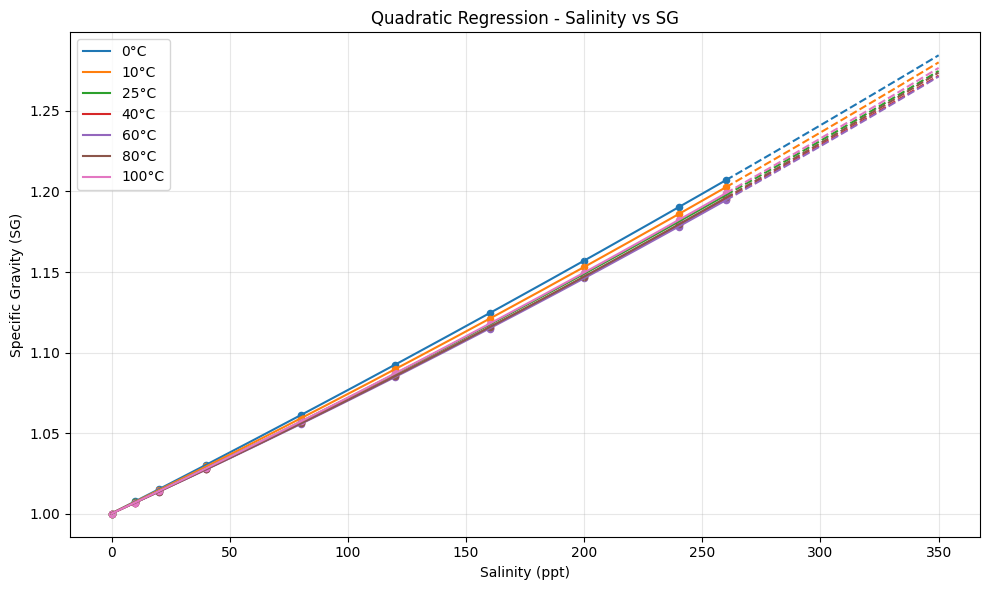

In [12]:
import matplotlib.pyplot as plt

ppt_fit = np.linspace(0, 260, 300)
ppt_extra = np.linspace(260, 350, 120)

plt.figure(figsize=(10, 6))

for temp, coef, sg_data in zip(temperatures, models, sg_table.T):
    line, = plt.plot(ppt_fit, np.polyval(coef, ppt_fit), label=f"{temp:g}°C")

    # data reference
    plt.scatter(
        salinities,
        sg_data,
        color=line.get_color(),
        s=20
    )

    # Extrapolation (ppt > 260)
    plt.plot(
        ppt_extra,
        np.polyval(coef, ppt_extra),
        "--",
        color=line.get_color()
    )


plt.xlabel("Salinity (ppt)")
plt.ylabel("Specific Gravity (SG)")
plt.title("Quadratic Regression - Salinity vs SG")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
def predict_sg(ppt, temperature):
    if ppt < 0 or not 0 <= temperature <= 100:
        return None

    # cari dua temperatur referensi terdekat
    i = np.searchsorted(temperatures, temperature, side="right") - 1
    i = int(np.clip(i, 0, len(temperatures) - 2))

    t0 = temperatures[i]
    t1 = temperatures[i + 1]

    # prediksi 2 model
    sg_pred0 = np.polyval(models[i], ppt)
    sg_pred1 = np.polyval(models[i + 1], ppt)

    # interpolasi hasil prediksi
    f = (temperature - t0) / (t1 - t0)
    sg_pred = sg_pred0 + f * (sg_pred1 - sg_pred0)

    return sg_pred

ppt = 33
temperature = 42

# ppt -> SG
sg = predict_sg(ppt, temperature)

if sg is not None:
    # SG -> Baume
    baume = 145.0 - 145.0 / sg
    print(f"Salinity (ppt) : {ppt} ppt")
    print(f"Temperature : {temperature} C")
    print(f"SG : {sg:.5f}")
    print(f"Baume : {baume:.2f} Be")

Salinity (ppt) : 33 ppt
Temperature : 42 C
SG : 1.02277
Baume : 3.23 Be
